In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

1. Import the WeatherData.csv from the dataset folder.

In [47]:
df=pd.read_csv('Datasets/Linear_Regression_WeatherData.csv')
df

,Temperature(C),Humidity
0,9.472222,0.89
1,9.355556,0.86
2,9.377778,0.89
3,8.288889,0.83
4,8.755556,0.83
5,9.222222,0.85
6,7.733333,0.95
7,8.772222,0.89
8,10.822222,0.82
9,13.772222,0.72


2. Remove the ( C ) from temperature column name. 

In [48]:
df=df.rename(columns={'Temperature(C)': 'Temperature'})

In [49]:
df

,Temperature,Humidity
0,9.472222,0.89
1,9.355556,0.86
2,9.377778,0.89
3,8.288889,0.83
4,8.755556,0.83
5,9.222222,0.85
6,7.733333,0.95
7,8.772222,0.89
8,10.822222,0.82
9,13.772222,0.72


3. Select X= Temperature and y=Humidity 

In [50]:
X=df[['Temperature']] 
print(X.shape)# Xshould be two dimensional 
y=df['Humidity'] 

(50, 1)


In [51]:
x_train,x_test,y_train,y_test=train_test_split(X, y, test_size=0.2, random_state=0)


4. Build a machine learning model ie regression model since y 
is continuous number  

In [52]:
model1=LinearRegression()

In [53]:
model1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.04]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.156
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [54]:
y_pred1 = model1.predict(x_test) 

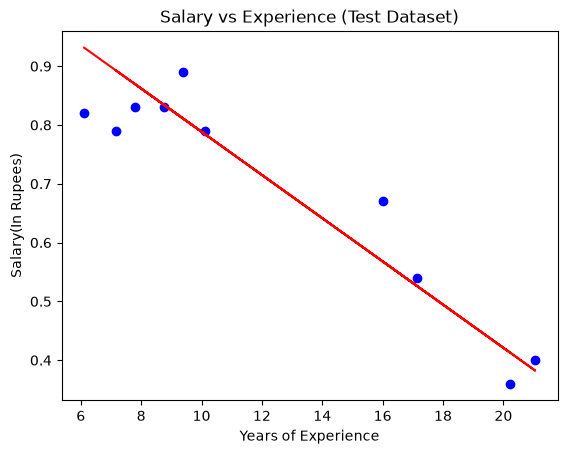

In [55]:
#visualizing the Test set results 
plt.scatter(x_test, y_test, color="blue") 
plt.plot(x_test, y_pred1, color="red") 
plt.title("Salary vs Experience (Test Dataset)") 
plt.xlabel("Years of Experience") 
plt.ylabel("Salary(In Rupees)") 
plt.show() 

In [56]:
mae1=mean_absolute_error(y_test,y_pred1)
mse1=mean_squared_error(y_test,y_pred1)
r2score1=r2_score(y_test,y_pred1)
rmse1=np.sqrt(mse1)

print("MAE: ",mae1)
print("MSE: ",mse1)
print("RMSE: ",rmse1)
print("r2_score: ",r2score1)

MAE:  0.052972201325354996
MSE:  0.004466590267614322
RMSE:  0.06683255395100746
r2_score:  0.865447937473963


5. Approximate the Temperature column to 4 decimal point and 
retrain the model. Value approximation can train the model 
efficiently and improve the accuracy of the model. * 
Approximation is not the main solution to improve the model, 
trial and run different possible ways.

In [57]:
df['Temperature'] = df['Temperature'].round(4)


In [58]:
X = df[['Temperature']]
y = df['Humidity']

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [60]:
model2=LinearRegression()

In [61]:
model2.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.6642
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [62]:
y_pred2=model2.predict(x_test)

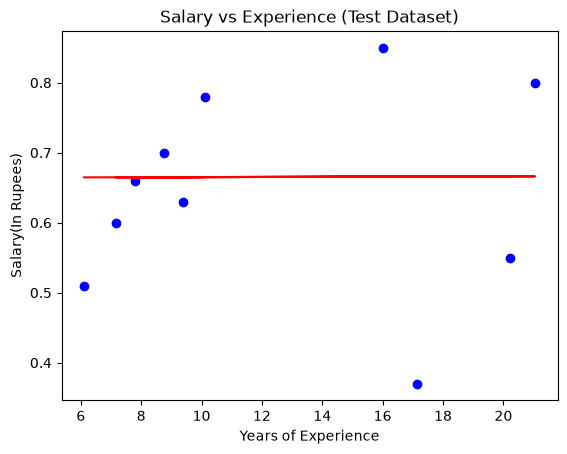

In [63]:
#visualizing the Test set results 
plt.scatter(x_test, y_test, color="blue") 
plt.plot(x_test, y_pred2, color="red") 
plt.title("Salary vs Experience (Test Dataset)") 
plt.xlabel("Years of Experience") 
plt.ylabel("Salary(In Rupees)") 
plt.show() 

In [64]:
mae2=mean_absolute_error(y_test,y_pred2)
mse2=mean_squared_error(y_test,y_pred2)
r2score2=r2_score(y_test,y_pred2)
rmse2=np.sqrt(mse2)

print("MAE: ",mae2)
print("MSE: ",mse2)
print("RMSE: ",rmse2)
print("r2_score: ",r2score2)

MAE:  0.11395178526984644
MSE:  0.01966919019148932
RMSE:  0.1402468901312586
r2_score:  -0.020980544588077743


6. Round off to 1 decimal point and evaluate the model.

In [65]:
df['Temperature'] = df['Temperature'].round(1)


In [66]:
X = df[['Temperature']]
y = df['Humidity']

In [67]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [68]:
model3=LinearRegression()

In [69]:
model3.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.6642
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [70]:
y_pred3=model3.predict(x_test)

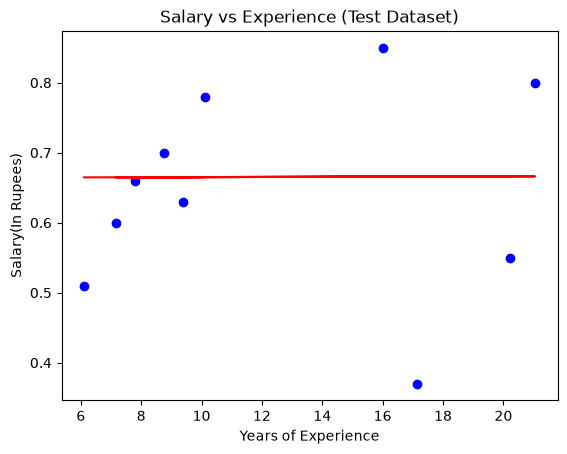

In [71]:
#visualizing the Test set results 
plt.scatter(x_test, y_test, color="blue") 
plt.plot(x_test, y_pred3, color="red") 
plt.title("Salary vs Experience (Test Dataset)") 
plt.xlabel("Years of Experience") 
plt.ylabel("Salary(In Rupees)") 
plt.show() 

In [72]:
mae3=mean_absolute_error(y_test,y_pred2)
mse3=mean_squared_error(y_test,y_pred2)
r2score3=r2_score(y_test,y_pred2)
rmse3=np.sqrt(mse3)

print("MAE: ",mae3)
print("MSE: ",mse3)
print("RMSE: ",rmse3)
print("r2_score: ",r2score3)

MAE:  0.11395178526984644
MSE:  0.01966919019148932
RMSE:  0.1402468901312586
r2_score:  -0.020980544588077743


In [73]:
output={
    'model1':{
        'mse':mse1,
        'mae':mae1,
        'mse':mse1,
        'rmse':rmse1,
        'r2_score':r2score1,
        'accuracy':r2score1*100
    },
    'model2_round(4)':{
        'mse':mse2,
        'mae':mae2,
        'mse':mse2,
        'rmse':rmse2,
        'r2_score':r2score2,
        'accuracy':r2score2*100
    },
    'model3_round(1)':{
        'mse':mse3,
        'mae':mae3,
        'mse':mse3,
        'rmse':rmse3,
        'r2_score':r2score3,
        'accuracy':r2score3*100
    }
}

In [75]:
print(output['model1'])
print()
print(output['model2_round(4)'])
print()
print(output['model3_round(1)'])

{'mse': 0.004466590267614322, 'mae': 0.052972201325354996, 'rmse': np.float64(0.06683255395100746), 'r2_score': 0.865447937473963, 'accuracy': 86.5447937473963}

{'mse': 0.01966919019148932, 'mae': 0.11395178526984644, 'rmse': np.float64(0.1402468901312586), 'r2_score': -0.020980544588077743, 'accuracy': -2.0980544588077743}

{'mse': 0.01966919019148932, 'mae': 0.11395178526984644, 'rmse': np.float64(0.1402468901312586), 'r2_score': -0.020980544588077743, 'accuracy': -2.0980544588077743}
